# dSprites Simulation Results

Continuous actions, cross-fitted DR weights (clipped at 5), Riesz flow, disjoint
autoencoder split. Sweep: $n_{\mathrm{obs}} \in \{500 \dots 8000\}$ (the causal
half is $n_{\mathrm{obs}}/2$), 10 DGP seeds, 3 repeats. Metrics are means over 10
fresh matched-size counterfactual reference draws; the reachable pixel floor is
clean sprites at oracle positions (the decoder denoises by construction).

The headline metric is the DecFM paper's: **SW2 in flat pixel space between the
decoded flow output and held-out counterfactual samples** (1000 projections),
arms averaged within each run, repeats within each seed, mean $\pm$ sd across
seeds. "No flow" scores the observed arm the same way; "floor" is
counterfactual-vs-counterfactual.

In [1]:
import glob

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.width", 140)


def load_results(pattern):
    "Concatenate every parsable task CSV (skips files a running task has not filled)."
    frames = []
    for f in sorted(glob.glob(pattern)):
        try:
            frames.append(pd.read_csv(f))
        except Exception:
            pass
    frame = pd.concat(frames, ignore_index=True)
    print(f"{len(frames)} files -> {len(frame)} rows")
    return frame


def headline(frame, value, by):
    '''Mean +/- sd of `value` vs the swept parameter(s) `by`.

    Aggregation order (the DecFM paper convention): arms averaged within each
    run first, then repeats within each data seed, then mean +/- sd across seeds.
    '''
    per_run = frame.groupby([*by, "data_seed", "repeat"])[value].mean()
    per_seed = per_run.groupby([*by, "data_seed"]).mean()
    return per_seed.groupby(list(by)).agg(["mean", "std"])


def sweep_table(frame, columns, by):
    "One table: each (column -> label) as `mean +- sd` against the swept parameter."
    out = {}
    for column, label in columns.items():
        stats = headline(frame, column, by)
        out[label] = (stats["mean"].map("{:.4f}".format) + " ± "
                      + stats["std"].map("{:.4f}".format))
    return pd.DataFrame(out)


def sweep_plot(ax, frame, columns, by, xlabel, logx=True):
    "Flow curve with a seed band; baselines as plain lines."
    styles = {"flow": ("tab:blue", "-"), "no flow": ("tab:red", ":"),
              "floor": ("tab:green", "--")}
    for column, label in columns.items():
        key = ("flow" if "flow" in label and "no" not in label
               else "no flow" if "no" in label else "floor")
        color, ls = styles[key]
        stats = headline(frame, column, by)
        ax.plot(stats.index, stats["mean"], marker="o", ms=4, color=color,
                linestyle=ls, label=label)
        if key == "flow":
            ax.fill_between(stats.index, stats["mean"] - stats["std"],
                            stats["mean"] + stats["std"], color=color, alpha=0.15)
    if logx:
        ax.set_xscale("log")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("pixel SW2 to counterfactual samples")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.25)

results = load_results("../dSprites/dr_mmd_flow/results/dsprites_splitae_*.csv")
COLUMNS = {"sw2_flow_mean": "SW2 flow", "sw2_logged_mean": "SW2 no flow",
           "sw2_floor_clean_mean": "SW2 floor (clean)"}

50 files -> 150 rows


## SW2 vs sample size

In [2]:
sweep_table(results, COLUMNS, ["n_obs"])

,SW2 flow,SW2 no flow,SW2 floor (clean)
n_obs,,,
500,0.0384 ± 0.0018,0.0585 ± 0.0037,0.0272 ± 0.0008
1000,0.0284 ± 0.0016,0.0553 ± 0.0017,0.0203 ± 0.0007
2000,0.0229 ± 0.0018,0.0552 ± 0.0024,0.0160 ± 0.0004
4000,0.0172 ± 0.0008,0.0536 ± 0.0012,0.0128 ± 0.0003
8000,0.0147 ± 0.0008,0.0538 ± 0.0011,0.0110 ± 0.0001


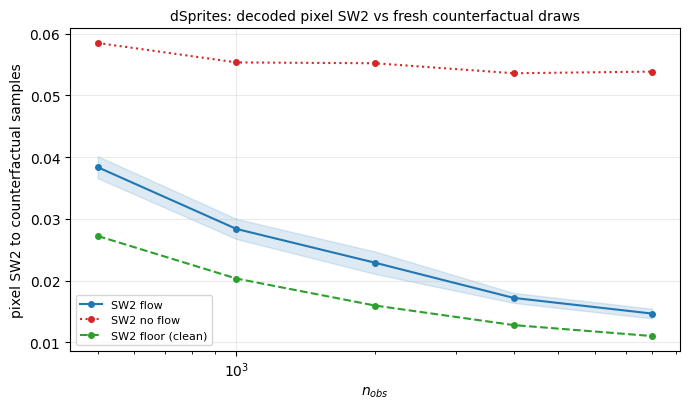

In [3]:
fig, ax = plt.subplots(figsize=(7, 4.2))
sweep_plot(ax, results, COLUMNS, ["n_obs"], "$n_{obs}$")
ax.set_title("dSprites: decoded pixel SW2 vs fresh counterfactual draws",
             fontsize=10)
fig.tight_layout()
plt.show()

## Summary

- SW2 falls monotonically $0.0384 \to 0.0147$ ($n = 500 \to 8000$), tracking the
  clean floor at a stable $\approx 1.3$–$1.4\times$ at every size.
- Weight clipping (default 5, selected by search) removed the low-ESS heavy tail
  of the unclipped first run; energy distance, SW1 and SW2 rank runs identically
  (Spearman $\ge 0.999$).